# Session 13 Assignment — 20M LLM on 50M tokens: Standard vs Reversible (Euler / Midpoint)

**Assignment (Session 13, §18 + class transcript):**
1. Train a ~20M LLM for 50M tokens. *Fix the batch size* = the biggest batch the standard model can run.
2. Train again **with reversibility** at the same batch — test **both variants (Euler and Midpoint)**, report which works.
3. Train again with reversibility, **pushed to the maximum batch size**.
4. Report final loss, speed (tokens/s), memory peak and other findings. Constraints from class: **no dropout, no weight decay** with reversibility (applied to all runs for a fair comparison).

**Run top-to-bottom (`Runtime → Run all`).** Estimated total on a T4 ≈ 60–70 min (L4 ≈ 30–35, A100 ≈ 15–20):

| Step | What |
|---|---|
| 1 | Build a 51M-token dataset (FineWeb-Edu stream → own 8k BPE tokenizer), ~5–8 min |
| 2–3 | Model (~21M params) + **correctness tests** (reversible grads == autograd grads) |
| 4 | Max-batch search for standard **and** reversible models (also gives the memory-vs-batch curve) |
| 5 | **Run 1** — standard, fixed batch = standard max batch, 50M tokens |
| 6 | **Run 2** — reversible at the same batch, **both Euler and Midpoint for the full 50M tokens**; the better loss trajectory is the winner |
| 7 | **Run 3** — winning reversible variant at its max batch, 50M tokens |
| 8 | Summary table, plots, cost estimate, `results.zip`, and one JSON line to paste back |

Each run saves to `RESULTS_DIR` and is **skipped if already finished** — after a disconnect just Run all again (`USE_DRIVE=True` survives a full reset).

**Reversible rules** (Gal et al., 2025, *Reversing Large Language Models for Efficient Training and Fine-Tuning*):
* **Midpoint:** $p^{\ell+1} = p^{\ell-1} + 2h\,f_{\theta_\ell}(p^{\ell})$, inverted as $p^{\ell-1} = p^{\ell+1} - 2h\,f_{\theta_\ell}(p^{\ell})$.
* **Euler** (symplectic / Hamiltonian, two coupled states): $q^{\ell} = q^{\ell-1} + \mathrm{Attn}_\ell(\mathrm{LN}_1(p^{\ell-1}))$, $p^{\ell} = p^{\ell-1} + \mathrm{MLP}_\ell(\mathrm{LN}_2(q^{\ell}))$, inverted by undoing the two updates in reverse order.

Neither stores per-layer activations: the backward pass rebuilds them from the top states.

In [1]:
# ---- 0. Setup ---------------------------------------------------------------
import os
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")  # less fragmentation -> larger max batch
!pip -q install datasets tokenizers

import math, time, json, gc, glob, shutil, subprocess
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.checkpoint import checkpoint

assert torch.cuda.is_available(), "Switch the runtime to a GPU (Runtime -> Change runtime type)."
DEVICE = "cuda"
cap = torch.cuda.get_device_capability()
AMP_DTYPE = torch.bfloat16 if cap >= (8, 0) else torch.float16      # T4 (7.5) -> fp16 + GradScaler
GPU_NAME = torch.cuda.get_device_name()
GPU_MEM_GIB = torch.cuda.get_device_properties(0).total_memory / 2**30
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
print(f"torch {torch.__version__} | {GPU_NAME} | {GPU_MEM_GIB:.1f} GiB | capability {cap} | AMP dtype {AMP_DTYPE}")

torch 2.11.0+cu128 | Tesla T4 | 14.6 GiB | capability (7, 5) | AMP dtype torch.float16


In [2]:
# ---- Config -----------------------------------------------------------------
USE_DRIVE = False          # True -> datasets & results persist in Google Drive across runtime resets
BASE_DIR = "/content/s13"
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = "/content/drive/MyDrive/s13"
DATA_DIR = f"{BASE_DIR}/data"
RESULTS_DIR = f"{BASE_DIR}/results"
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(RESULTS_DIR, exist_ok=True)

CFG = dict(
    vocab_size=8192, d_model=384, n_layers=10, n_heads=6, seq_len=512,   # ~21M params (tied embeddings)
    total_tokens=50_000_000, val_tokens=1_000_000,
    fixed_batch=None,           # None -> max batch of the STANDARD model (found in step 4); or set e.g. 64
    base_lr=1e-3, min_lr_frac=0.1, weight_decay=0.0, betas=(0.9, 0.95), grad_clip=1.0,   # no weight decay (class constraint)
    warmup_frac=0.02, lr_scale_rule="sqrt", max_lr=3e-3,   # Run 3 LR = base_lr*sqrt(B3/B1), capped
    gpu_usd_per_hour={"T4": 0.35, "L4": 0.70, "A100": 1.80, "H100": 2.50},   # rough cloud on-demand prices, edit freely
    ce_chunk_tokens=8192,       # chunked + checkpointed LM head so logits don't dominate memory (used for ALL runs)
    eval_every_tokens=5_000_000, eval_batches=40, eval_batch=16,
    sweep_tokens=5_000_000,     # tokens per variant in the Euler-vs-Midpoint head-to-head
    seed=1337,
)
FULL_BOTH = True    # Run 2 trains BOTH Euler and Midpoint for the full 50M tokens (as the assignment asks). False -> 5M-token shortcut
# Reversible variants (h = step size; gamma = blend coefficient, 1.0 = the paper's plain rule)
VARIANTS = {
    "euler":    dict(mode="euler",    h=1.0,  gamma=1.0),   # symplectic Euler / Hamiltonian coupling (a = b = 1)
    "midpoint": dict(mode="midpoint", h=0.25, gamma=1.0),   # p+ = p- + 2h f(p), h = 0.25 (Lightning LM step size)
    # "midpoint_blend": dict(mode="midpoint", h=0.25, gamma=0.5),   # optional 3rd variant (Lightning LM blend 0.5)
}
json.dump(dict(CFG=CFG, VARIANTS=VARIANTS, gpu=GPU_NAME, gpu_mem_gib=GPU_MEM_GIB, amp=str(AMP_DTYPE),
               torch=torch.__version__), open(f"{RESULTS_DIR}/env.json", "w"), indent=2)

## 1. Data — 51M tokens of FineWeb-Edu with our own 8,192-token BPE
A 50k-vocab GPT-2 tokenizer would put ~19M of the 20M parameters in the embedding table, so we train a small
byte-level BPE (8,192 tokens) on the streamed text. Output: `train.bin` (≥50M tokens) and `val.bin` (1M tokens), uint16.

In [3]:
from datasets import load_dataset
from tokenizers import ByteLevelBPETokenizer, Tokenizer

TOK_PATH, TRAIN_BIN, VAL_BIN = f"{DATA_DIR}/bpe8k.json", f"{DATA_DIR}/train.bin", f"{DATA_DIR}/val.bin"
NEED = CFG["total_tokens"] + CFG["seq_len"] * 64 + CFG["val_tokens"]

def stream_docs():
    ds = load_dataset("HuggingFaceFW/fineweb-edu", name="sample-10BT", split="train", streaming=True)
    for ex in ds:
        yield ex["text"]

if not (os.path.exists(TRAIN_BIN) and os.path.exists(VAL_BIN)):
    t0 = time.time()
    # 1a. tokenizer on the first ~60 MB of text
    if not os.path.exists(TOK_PATH):
        sample, n = [], 0
        for txt in stream_docs():
            sample.append(txt); n += len(txt)
            if n > 60_000_000: break
        bpe = ByteLevelBPETokenizer()
        bpe.train_from_iterator(sample, vocab_size=CFG["vocab_size"], min_frequency=2, special_tokens=["<|endoftext|>"])
        bpe.save(TOK_PATH); del sample
        print(f"tokenizer trained in {time.time()-t0:.0f}s")
    tok = Tokenizer.from_file(TOK_PATH)
    EOT = tok.token_to_id("<|endoftext|>")
    # 1b. encode until we have enough tokens
    out = np.empty(NEED + 200_000, dtype=np.uint16); pos = 0; buf = []
    for txt in stream_docs():
        buf.append(txt)
        if len(buf) == 2000:
            for enc in tok.encode_batch(buf):
                ids = enc.ids + [EOT]; m = min(len(ids), len(out) - pos)
                out[pos:pos+m] = ids[:m]; pos += m
            buf = []
            print(f"\r{pos/1e6:6.1f}M / {NEED/1e6:.1f}M tokens  ({time.time()-t0:.0f}s)", end="")
            if pos >= NEED: break
    out = out[:pos]
    val, train = out[:CFG["val_tokens"]], out[CFG["val_tokens"]:]
    train.tofile(TRAIN_BIN); val.tofile(VAL_BIN)
    print(f"\nsaved train={len(train):,} val={len(val):,} tokens in {time.time()-t0:.0f}s")

TRAIN = np.fromfile(TRAIN_BIN, dtype=np.uint16).astype(np.int32)
VAL = np.fromfile(VAL_BIN, dtype=np.uint16).astype(np.int32)
tok = Tokenizer.from_file(TOK_PATH)
print(f"train {len(TRAIN):,} tokens | val {len(VAL):,} tokens | chars/token ≈ "
      f"{len(tok.decode(TRAIN[:20000].tolist()))/20000:.2f}")
print(tok.decode(TRAIN[:80].tolist()))

README.md:   0%|          | 0.00/26.4k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/2410 [00:00<?, ?it/s]

tokenizer trained in 39s


Resolving data files:   0%|          | 0/2410 [00:00<?, ?it/s]

  51.2M / 51.0M tokens  (159s)
saved train=50,232,768 val=1,000,000 tokens in 159s
train 50,232,768 tokens | val 1,000,000 tokens | chars/token ≈ 4.11
 have identified a significant overlap between the populations of youth served by community mental health agencies and youth in contact with the community's juvenile court.23 These studies are few in number, but they have found that the risk of juvenile court involvement among a community's young mental health clients is substantial. For example, a study in one city found that adolescents in contact


In [4]:
T = CFG["seq_len"]
N_WINDOWS = (len(TRAIN) - 1) // T
_rng = np.random.default_rng(CFG["seed"])
ORDER = _rng.permutation(N_WINDOWS)          # one fixed shuffled order of non-overlapping windows, shared by all runs
_AR = np.arange(T + 1)

def get_batch(step, B):
    starts = ORDER[(step * B + np.arange(B)) % N_WINDOWS] * T
    w = torch.from_numpy(TRAIN[starts[:, None] + _AR].astype(np.int64)).pin_memory()
    w = w.to(DEVICE, non_blocking=True)
    return w[:, :-1], w[:, 1:]

_vr = np.random.default_rng(0)
VAL_STARTS = _vr.integers(0, len(VAL) - T - 1, size=CFG["eval_batches"] * CFG["eval_batch"])
def val_batches():
    for i in range(CFG["eval_batches"]):
        s = VAL_STARTS[i*CFG["eval_batch"]:(i+1)*CFG["eval_batch"]]
        w = torch.from_numpy(VAL[s[:, None] + _AR].astype(np.int64)).to(DEVICE)
        yield w[:, :-1], w[:, 1:]
print(f"{N_WINDOWS:,} training windows of {T} tokens")

98,110 training windows of 512 tokens


## 2. Model
Every variant uses **the same parameters**: a pre-LN transformer block, written as a *residual update*
$f(x) = a + \mathrm{MLP}(\mathrm{LN}_2(x+a))$, $a=\mathrm{Attn}(\mathrm{LN}_1(x))$. Only the rule that combines updates differs:

* **standard** (plain residual, not reversible): $p^{\ell+1} = p^\ell + f_\ell(p^\ell)$ — autograd stores every layer's activations.
* **midpoint** (leapfrog): $p^{\ell+1} = \gamma p^{\ell-1} + (1-\gamma)p^\ell + 2h f_\ell(p^\ell)$. First step is Euler $p^1 = p^0 + h f_0(p^0)$.
  A custom `autograd.Function` keeps only $(p^{L-1}, p^L)$ and rebuilds the rest backwards.
* **euler** (symplectic Euler, two coupled states $q, p$ both initialised to the embedding): $q \leftarrow q + \mathrm{Attn}(\mathrm{LN}_1(p))$, $p \leftarrow p + \mathrm{MLP}(\mathrm{LN}_2(q))$; output $= (q+p)/2$.

Dropout is 0 and weight decay is 0 everywhere (dropout is required to be 0: reconstruction must replay exactly the same function). The residual stream is kept in fp32;
blocks run under autocast. The LM head + cross-entropy is chunked and checkpointed in **all** runs so the 8k-vocab logits don't hide the activation savings.

In [5]:
class Attn(nn.Module):
    def __init__(s, d, nh):
        super().__init__(); s.nh = nh
        s.qkv = nn.Linear(d, 3 * d, bias=False); s.proj = nn.Linear(d, d, bias=False)
    def forward(s, x):
        B, T_, C = x.shape
        q, k, v = s.qkv(x).view(B, T_, 3, s.nh, C // s.nh).permute(2, 0, 3, 1, 4)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        return s.proj(y.transpose(1, 2).reshape(B, T_, C))

class MLP(nn.Module):
    def __init__(s, d):
        super().__init__(); s.fc = nn.Linear(d, 4 * d, bias=False); s.proj = nn.Linear(4 * d, d, bias=False)
    def forward(s, x): return s.proj(F.gelu(s.fc(x), approximate="tanh"))

class Block(nn.Module):
    def __init__(s, d, nh):
        super().__init__()
        s.ln1, s.attn, s.ln2, s.mlp = nn.LayerNorm(d), Attn(d, nh), nn.LayerNorm(d), MLP(d)
    def delta(s, x):                       # f(x) = block(x) - x  (used by standard & midpoint)
        a = s.attn(s.ln1(x))
        return a + s.mlp(s.ln2(x + a))
    def F_(s, x): return s.attn(s.ln1(x))  # Euler halves
    def G_(s, x): return s.mlp(s.ln2(x))

def _autocast(ctx, like):
    return torch.autocast(device_type=like.device.type, dtype=ctx.amp_dtype, enabled=ctx.amp)

def _amp_state():
    en = torch.is_autocast_enabled()
    try: dt = torch.get_autocast_dtype("cuda")
    except Exception: dt = torch.get_autocast_gpu_dtype()
    return en, dt

class RevMidpointFn(torch.autograd.Function):
    """p_{l+1} = g*p_{l-1} + (1-g)*p_l + 2h*f_l(p_l). Stores only the last two states."""
    @staticmethod
    def forward(ctx, p0, p1, h, gamma, blocks, *params):
        ctx.h, ctx.gamma, ctx.blocks = h, gamma, blocks
        ctx.amp, ctx.amp_dtype = _amp_state()
        prev, cur = p0, p1
        for b in blocks:
            prev, cur = cur, gamma * prev + (1 - gamma) * cur + (2 * h) * b.delta(cur).to(cur.dtype)
        ctx.save_for_backward(prev.detach(), cur.detach())
        return cur

    @staticmethod
    def backward(ctx, g_cur):
        prev, cur = ctx.saved_tensors          # (p_{L-1}, p_L)
        h, gm, blocks = ctx.h, ctx.gamma, ctx.blocks
        g_prev = torch.zeros_like(prev); g_cur = g_cur.to(prev.dtype)
        pgrads = []
        for b in reversed(blocks):
            bp = [p for p in b.parameters()]
            with torch.enable_grad(), _autocast(ctx, prev):
                x = prev.detach().requires_grad_(True)
                fx = b.delta(x).to(x.dtype)
            gs = torch.autograd.grad(fx, [x] + bp, grad_outputs=(2 * h) * g_cur, allow_unused=True)
            with torch.no_grad():
                p_lm1 = (cur - (1 - gm) * prev - (2 * h) * fx.detach()) / gm      # rebuild p_{l-1}
                new_g_prev = gm * g_cur                                          # grad of p_{l-1} so far
                new_g_cur = g_prev + (1 - gm) * g_cur + gs[0]                    # grad of p_l, complete
            pgrads.append(list(gs[1:]))
            prev, cur, g_prev, g_cur = p_lm1, prev, new_g_prev, new_g_cur
            del x, fx, gs
        flat = [g for blk in reversed(pgrads) for g in blk]
        return (g_prev, g_cur, None, None, None, *flat)

class RevEulerFn(torch.autograd.Function):
    """Symplectic Euler (Hamiltonian) coupling: q += Attn(LN1(p)); p += MLP(LN2(q)). Stores only final (q, p)."""
    @staticmethod
    def forward(ctx, x1, x2, blocks, *params):
        ctx.blocks = blocks; ctx.amp, ctx.amp_dtype = _amp_state()
        for b in blocks:
            x1 = x1 + b.F_(x2).to(x2.dtype)
            x2 = x2 + b.G_(x1).to(x1.dtype)
        ctx.save_for_backward(x1.detach(), x2.detach())
        return x1, x2

    @staticmethod
    def backward(ctx, g1, g2):
        y1, y2 = ctx.saved_tensors
        g1, g2 = g1.to(y1.dtype), g2.to(y1.dtype)
        pgrads = []
        for b in reversed(ctx.blocks):
            bp = [p for p in b.parameters()]
            with torch.enable_grad(), _autocast(ctx, y1):
                y1_ = y1.detach().requires_grad_(True); gout = b.G_(y1_).to(y1_.dtype)
            gg = torch.autograd.grad(gout, [y1_] + bp, grad_outputs=g2, allow_unused=True)
            with torch.no_grad():
                x2 = y2 - gout.detach(); g1 = g1 + gg[0]
            with torch.enable_grad(), _autocast(ctx, y1):
                x2_ = x2.detach().requires_grad_(True); fout = b.F_(x2_).to(x2_.dtype)
            gf = torch.autograd.grad(fout, [x2_] + bp, grad_outputs=g1, allow_unused=True)
            with torch.no_grad():
                x1 = y1 - fout.detach(); g2 = g2 + gf[0]
            pg = [(a if a is not None else 0) + (c if c is not None else 0) for a, c in zip(gg[1:], gf[1:])]
            pgrads.append([p if torch.is_tensor(p) else None for p in pg])
            y1, y2 = x1, x2
            del y1_, gout, x2_, fout, gg, gf
        flat = [g for blk in reversed(pgrads) for g in blk]
        return (g1, g2, None, *flat)

def lm_loss(hid, W, targets, chunk):
    hid = hid.reshape(-1, hid.shape[-1]); t = targets.reshape(-1); N = t.numel()
    ce = lambda hc, tc: F.cross_entropy(F.linear(hc, W).to(torch.promote_types(hc.dtype, torch.float32)), tc, reduction="sum")
    if chunk <= 0 or N <= chunk:
        return ce(hid, t) / N
    tot = 0.0
    for i in range(0, N, chunk):
        tot = tot + checkpoint(ce, hid[i:i+chunk], t[i:i+chunk], use_reentrant=False)
    return tot / N

class GPT(nn.Module):
    def __init__(s, cfg, mode="standard", h=1.0, gamma=1.0, memsave=True):
        super().__init__()
        d, L = cfg["d_model"], cfg["n_layers"]
        s.mode, s.h, s.gamma, s.memsave, s.chunk = mode, h, gamma, memsave, cfg["ce_chunk_tokens"]
        s.tok = nn.Embedding(cfg["vocab_size"], d); s.pos = nn.Embedding(cfg["seq_len"], d)
        s.blocks = nn.ModuleList([Block(d, cfg["n_heads"]) for _ in range(L)])
        s.ln_f = nn.LayerNorm(d)
        s.apply(s._init)
        for n, p in s.named_parameters():
            if n.endswith("proj.weight"): nn.init.normal_(p, 0.0, 0.02 / math.sqrt(2 * L))
    def _init(s, m):
        if isinstance(m, (nn.Linear, nn.Embedding)): nn.init.normal_(m.weight, 0.0, 0.02)

    def trunk(s, idx):
        Tn = idx.shape[1]
        x = s.tok(idx) + s.pos(torch.arange(Tn, device=idx.device))
        rd = x.dtype                      # residual stream dtype: fp32 (fp64 in the gradient test)
        blocks = list(s.blocks)
        if s.mode == "standard":
            for b in blocks: x = x + b.delta(x).to(rd)
            return x
        if s.mode == "midpoint":
            p0 = x; p1 = p0 + s.h * blocks[0].delta(p0).to(rd)     # Euler start (1 layer stored normally)
            rest = blocks[1:]
            if s.memsave:
                params = [p for b in rest for p in b.parameters()]
                return RevMidpointFn.apply(p0, p1, s.h, s.gamma, rest, *params)
            prev, cur = p0, p1
            for b in rest: prev, cur = cur, s.gamma * prev + (1 - s.gamma) * cur + 2 * s.h * b.delta(cur).to(rd)
            return cur
        if s.mode == "euler":
            if s.memsave:
                params = [p for b in blocks for p in b.parameters()]
                y1, y2 = RevEulerFn.apply(x, x, blocks, *params)
            else:
                y1, y2 = x, x
                for b in blocks:
                    y1 = y1 + b.F_(y2).to(rd); y2 = y2 + b.G_(y1).to(rd)
            return 0.5 * (y1 + y2)
        raise ValueError(s.mode)

    def forward(s, idx, targets):
        return lm_loss(s.ln_f(s.trunk(idx)), s.tok.weight, targets, s.chunk)

m = GPT(CFG)
N_PARAMS = sum(p.numel() for p in m.parameters())
print(f"params: {N_PARAMS/1e6:.2f}M total | {(N_PARAMS - m.tok.weight.numel() - m.pos.weight.numel())/1e6:.2f}M non-embedding")
del m

params: 21.05M total | 17.71M non-embedding


## 3. Correctness tests (must pass before training)
1. **Gradient equivalence**: memory-saving reversible backward vs plain autograd through the *same* rule, in float64 on a tiny model → should agree to ~1e-10.
2. Same test at real size in fp32 on GPU and under autocast.
3. **Reconstruction error**: run forward, then run the rule backward from the top two states and compare the rebuilt input with the true input.

In [6]:
def grad_compare(mode, h, gamma, cfg, dtype, device, amp=False, B=2):
    torch.manual_seed(0)
    a = GPT(cfg, mode, h, gamma, memsave=True).to(device, dtype)
    b = GPT(cfg, mode, h, gamma, memsave=False).to(device, dtype); b.load_state_dict(a.state_dict())
    x = torch.randint(0, cfg["vocab_size"], (B, cfg["seq_len"]), device=device); y = torch.roll(x, -1, 1)
    res = []
    for mdl in (a, b):
        with torch.autocast("cuda", dtype=AMP_DTYPE, enabled=amp):
            loss = mdl(x, y)
        loss.backward(); res.append((loss.item(), [p.grad.detach().float().clone() for p in mdl.parameters()]))
    (la, ga), (lb, gb) = res
    rel = max(((u - v).norm() / (v.norm() + 1e-30)).item() for u, v in zip(ga, gb))
    return abs(la - lb), rel

tiny = dict(CFG, d_model=32, n_layers=6, n_heads=4, seq_len=16, vocab_size=64, ce_chunk_tokens=8)
print("float64, CPU, tiny model  (loss diff, max relative grad diff)")
for name, v in VARIANTS.items():
    dl, rel = grad_compare(v["mode"], v["h"], v["gamma"], tiny, torch.float64, "cpu")
    print(f"  {name:15s} {dl:.2e}  {rel:.2e}"); assert rel < 1e-6, f"{name} gradient mismatch!"
print("fp32 / autocast, GPU, real model")
for name, v in VARIANTS.items():
    r32 = grad_compare(v["mode"], v["h"], v["gamma"], CFG, torch.float32, DEVICE)
    ramp = grad_compare(v["mode"], v["h"], v["gamma"], CFG, torch.float32, DEVICE, amp=True)
    print(f"  {name:15s} fp32: {r32[1]:.2e} | autocast {AMP_DTYPE}: {ramp[1]:.2e}")
    assert r32[1] < 1e-2, f"{name} fp32 gradient mismatch!"
torch.cuda.empty_cache()

float64, CPU, tiny model  (loss diff, max relative grad diff)
  euler           0.00e+00  0.00e+00
  midpoint        0.00e+00  0.00e+00
fp32 / autocast, GPU, real model
  euler           fp32: 8.74e-06 | autocast torch.float16: 7.85e-03
  midpoint        fp32: 1.70e-06 | autocast torch.float16: 1.30e-02


In [7]:
@torch.no_grad()
def reconstruction_error(model, idx, amp=True):
    """Forward through the rule, then invert from the top pair; returns relative error of the rebuilt input."""
    with torch.autocast("cuda", dtype=AMP_DTYPE, enabled=amp):
        x = (model.tok(idx) + model.pos(torch.arange(idx.shape[1], device=idx.device))).float()
        bl = list(model.blocks)
        if model.mode == "midpoint":
            h, g = model.h, model.gamma
            p0 = x; prev, cur = p0, p0 + h * bl[0].delta(p0).float()
            p1 = cur
            for b in bl[1:]: prev, cur = cur, g * prev + (1 - g) * cur + 2 * h * b.delta(cur).float()
            for b in reversed(bl[1:]):
                prev, cur = (cur - (1 - g) * prev - 2 * h * b.delta(prev).float()) / g, prev
            return ((prev - p0).norm() / p0.norm()).item(), ((cur - p1).norm() / p1.norm()).item()
        if model.mode == "euler":
            y1, y2 = x, x
            for b in bl: y1 = y1 + b.F_(y2).float(); y2 = y2 + b.G_(y1).float()
            for b in reversed(bl): y2 = y2 - b.G_(y1).float(); y1 = y1 - b.F_(y2).float()
            return ((y1 - x).norm() / x.norm()).item(), ((y2 - x).norm() / x.norm()).item()
    return 0.0, 0.0

xb, _ = get_batch(0, 8)
for name, v in VARIANTS.items():
    torch.manual_seed(0); mm = GPT(CFG, v["mode"], v["h"], v["gamma"]).to(DEVICE)
    print(f"{name:15s} reconstruction rel. error at init (autocast): {reconstruction_error(mm, xb)}")
del mm; torch.cuda.empty_cache()

euler           reconstruction rel. error at init (autocast): (0.0008705835789442062, 0.0022677320521324873)
midpoint        reconstruction rel. error at init (autocast): (0.0010164534905925393, 0.0008068184833973646)


## Training utilities
* **Throughput** (tokens/s) = tokens / wall time of optimizer steps only: the first 10 steps (warm-up) and eval time are excluded.
  The GPU is synchronised only at log points, so timing adds no per-step overhead.
* **Memory peak** = `torch.cuda.max_memory_allocated()` over the whole run (plus `max_memory_reserved`, what `nvidia-smi` roughly shows).
* Val loss is on a fixed 327k-token held-out set, identical for every run.

In [8]:
def lr_at(step, steps, peak, warm, min_frac):
    if step < warm: return peak * (step + 1) / warm
    p = (step - warm) / max(1, steps - warm)
    return peak * (min_frac + (1 - min_frac) * 0.5 * (1 + math.cos(math.pi * p)))

def make_opt(model, lr):
    return torch.optim.AdamW(model.parameters(), lr=lr, betas=CFG["betas"],
                             weight_decay=CFG["weight_decay"], fused=True)

@torch.no_grad()
def evaluate(model):
    model.eval(); tot = 0.0
    for x, y in val_batches():
        with torch.autocast("cuda", dtype=AMP_DTYPE): tot += model(x, y).item()
    model.train(); return tot / CFG["eval_batches"]

def lr_for_batch(B):
    B1 = CFG["fixed_batch"]
    if B == B1: return CFG["base_lr"]
    s = (B / B1) ** (0.5 if CFG["lr_scale_rule"] == "sqrt" else 1.0)
    return min(CFG["base_lr"] * s, CFG["max_lr"])

def gpu_price():
    for k, v in CFG["gpu_usd_per_hour"].items():
        if k in GPU_NAME: return v
    return float("nan")

def train_run(name, mode="standard", h=1.0, gamma=1.0, B=None, tokens=None, lr=None, log_every=25, force=False):
    path = f"{RESULTS_DIR}/{name}.json"
    if os.path.exists(path) and not force:
        r = json.load(open(path)); print(f"[{name}] already done -> val {r['final_val_loss']:.4f}"); return r
    B = B or CFG["fixed_batch"]; tokens = tokens or CFG["total_tokens"]; lr = lr or lr_for_batch(B)
    steps = min(tokens // (B * T), N_WINDOWS // B)
    log_every = max(1, min(log_every, steps // 20))
    warm = max(10, int(CFG["warmup_frac"] * steps))
    eval_every = max(1, round(CFG["eval_every_tokens"] / (B * T) / log_every)) * log_every   # multiple of log_every
    torch.manual_seed(CFG["seed"]); gc.collect(); torch.cuda.empty_cache()
    model = GPT(CFG, mode, h, gamma).to(DEVICE); opt = make_opt(model, lr)
    scaler = torch.amp.GradScaler("cuda", enabled=(AMP_DTYPE == torch.float16))
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    log, evals = [], []
    train_time, timed_tokens, tokens_since, mark = 0.0, 0, 0, None
    t_wall = time.time(); diverged = False
    print(f"[{name}] mode={mode} h={h} gamma={gamma} B={B} ({B*T:,} tok/step) steps={steps} lr={lr:.2e}")
    for step in range(steps):
        for g in opt.param_groups: g["lr"] = lr_at(step, steps, lr, warm, CFG["min_lr_frac"])
        x, y = get_batch(step, B)
        with torch.autocast("cuda", dtype=AMP_DTYPE):
            loss = model(x, y)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        gn = torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
        scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
        tokens_since += B * T
        is_log = (step + 1) % log_every == 0 or step == steps - 1 or step == 9
        if not is_log: continue
        li = loss.item(); torch.cuda.synchronize(); now = time.perf_counter()
        if mark is not None: train_time += now - mark; timed_tokens += tokens_since
        tokens_since, mark = 0, now
        tps = timed_tokens / train_time if train_time > 0 else float("nan")
        log.append(dict(step=step + 1, tokens=(step + 1) * B * T, loss=li, lr=opt.param_groups[0]["lr"],
                        gnorm=float(gn), tok_s=tps))
        if (step + 1) % (log_every * 8) == 0 or step == steps - 1:
            print(f"  step {step+1:5d}/{steps} | loss {li:.4f} | {tps/1e3:6.1f}k tok/s | "
                  f"peak {torch.cuda.max_memory_allocated()/2**30:.2f} GiB | {time.time()-t_wall:.0f}s")
        if not math.isfinite(li):
            print("  !! non-finite loss, stopping"); diverged = True; break
        if (step + 1) % eval_every == 0 or step == steps - 1:
            vl = evaluate(model); evals.append(dict(step=step + 1, tokens=(step + 1) * B * T, val_loss=vl))
            print(f"  >> val loss {vl:.4f} @ {(step+1)*B*T/1e6:.1f}M tokens")
            mark = time.perf_counter()                      # exclude eval time
    if not evals: evals.append(dict(step=step + 1, tokens=(step + 1) * B * T, val_loss=float("nan")))
    rec = reconstruction_error(model, get_batch(0, 8)[0]) if mode != "standard" else None
    tps = timed_tokens / max(train_time, 1e-9)
    res = dict(name=name, mode=mode, h=h, gamma=gamma, batch=B, seq_len=T, tokens_per_step=B * T, steps=steps, lr=lr,
               tokens=steps * B * T, params=N_PARAMS, diverged=diverged,
               final_train_loss=float(np.mean([l["loss"] for l in log[-5:]])), final_val_loss=evals[-1]["val_loss"],
               tok_per_s=tps, train_time_s=train_time, wall_time_s=time.time() - t_wall,
               est_time_50M_min=CFG["total_tokens"] / tps / 60,
               est_cost_50M_usd=CFG["total_tokens"] / tps / 3600 * gpu_price(),
               peak_mem_alloc_gib=torch.cuda.max_memory_allocated() / 2**30,
               peak_mem_reserved_gib=torch.cuda.max_memory_reserved() / 2**30,
               reconstruction_rel_err_after_training=rec,
               gpu=GPU_NAME, amp=str(AMP_DTYPE), log=log, evals=evals)
    json.dump(res, open(path, "w"), indent=1)
    print(f"[{name}] DONE val {res['final_val_loss']:.4f} | train {res['final_train_loss']:.4f} | "
          f"{tps/1e3:.1f}k tok/s | peak {res['peak_mem_alloc_gib']:.2f} GiB")
    del model, opt; gc.collect(); torch.cuda.empty_cache()
    return res

def train_run_safe(name, *a, B, **k):
    """If a long run OOMs (fragmentation) at the searched max batch, retry 8 smaller."""
    while True:
        r = None
        try:
            r = train_run(name, *a, B=B, **k)
        except torch.cuda.OutOfMemoryError:
            print(f"  OOM at B={B} -> retry with B={B-8}"); B -= 8
        gc.collect(); torch.cuda.empty_cache()
        if r is not None: return r

## 4. Maximum batch search (standard and reversible)
A full training step (forward + backward + AdamW) at growing batch sizes until OOM, then binary search to a multiple of 8.
Peak memory at every batch tried gives the **memory-vs-batch slope** = activation memory per 512-token sequence —
the cleanest measure of what reversibility saves. The standard model's max batch becomes the fixed batch for Runs 1 and 2.

In [9]:
def try_batch(mode, h, gamma, B):
    model = opt = x = y = loss = None
    gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    try:
        torch.manual_seed(0)
        model = GPT(CFG, mode, h, gamma).to(DEVICE); opt = make_opt(model, 1e-4)
        for i in range(2):
            x, y = get_batch(i, B)
            with torch.autocast("cuda", dtype=AMP_DTYPE): loss = model(x, y)
            loss.backward(); opt.step(); opt.zero_grad(set_to_none=True)
        torch.cuda.synchronize()
        return torch.cuda.max_memory_allocated() / 2**30
    except torch.cuda.OutOfMemoryError:
        return None
    finally:
        del model, opt, x, y, loss; gc.collect(); torch.cuda.empty_cache()

def find_max_batch(mode, h=1.0, gamma=1.0, start=16, gran=8, cap=16384):
    curve = {}; lo, hi, B = 0, None, start
    while B <= cap:
        m = try_batch(mode, h, gamma, B); print(f"  B={B:5d} -> {'OOM' if m is None else f'{m:.2f} GiB'}")
        if m is None: hi = B; break
        curve[B] = m; lo = B; B *= 2
    if hi is None: return lo, curve
    while hi - lo > gran:
        mid = (lo + hi) // 2 // gran * gran
        if mid <= lo: break
        m = try_batch(mode, h, gamma, mid); print(f"  B={mid:5d} -> {'OOM' if m is None else f'{m:.2f} GiB'}")
        if m is None: hi = mid
        else: lo = mid; curve[mid] = m
    return lo, curve

def slope(curve):   # GiB per extra sequence (least squares)
    xs = np.array([int(k) for k in curve]); ys = np.array(list(curve.values()))
    return float(np.polyfit(xs, ys, 1)[0]) if len(xs) > 1 else float("nan")

MB_PATH = f"{RESULTS_DIR}/max_batch.json"
MAXB = json.load(open(MB_PATH)) if os.path.exists(MB_PATH) else {}
for key, (mode, h, g) in {"standard": ("standard", 1.0, 1.0),
                          **{k: (v["mode"], v["h"], v["gamma"]) for k, v in VARIANTS.items()}}.items():
    if key in MAXB: continue
    print(f"{key}:"); b, c = find_max_batch(mode, h, g)
    MAXB[key] = dict(max_batch=b, curve={str(k): v for k, v in c.items()}, gib_per_seq=slope(c))
    json.dump(MAXB, open(MB_PATH, "w"), indent=1)
for k, v in MAXB.items():
    print(f"{k:10s} max batch {v['max_batch']:5d} ({v['max_batch']*T:,} tok/step) | "
          f"{v['gib_per_seq']*1024:6.1f} MiB per 512-token sequence | "
          f"{v['max_batch']/MAXB['standard']['max_batch']:.2f}x standard")
if CFG["fixed_batch"] is None:
    CFG["fixed_batch"] = MAXB["standard"]["max_batch"]
print(f"==> fixed batch for Runs 1 & 2: {CFG['fixed_batch']} sequences x {T} = {CFG['fixed_batch']*T:,} tokens/step")

standard:
  B=   16 -> 2.12 GiB
  B=   32 -> 3.24 GiB
  B=   64 -> 5.42 GiB
  B=  128 -> 9.80 GiB
  B=  256 -> OOM
  B=  192 -> 14.17 GiB
  B=  224 -> OOM
  B=  208 -> OOM
  B=  200 -> OOM
euler:
  B=   16 -> 1.05 GiB
  B=   32 -> 1.14 GiB
  B=   64 -> 1.25 GiB
  B=  128 -> 1.88 GiB
  B=  256 -> 3.43 GiB
  B=  512 -> 6.53 GiB
  B= 1024 -> 12.74 GiB
  B= 2048 -> OOM
  B= 1536 -> OOM
  B= 1280 -> OOM
  B= 1152 -> 14.29 GiB
  B= 1216 -> OOM
  B= 1184 -> OOM
  B= 1168 -> OOM
  B= 1160 -> OOM
midpoint:
  B=   16 -> 1.15 GiB
  B=   32 -> 1.33 GiB
  B=   64 -> 1.66 GiB
  B=  128 -> 3.00 GiB
  B=  256 -> 5.68 GiB
  B=  512 -> 11.03 GiB
  B= 1024 -> OOM
  B=  768 -> OOM
  B=  640 -> 13.71 GiB
  B=  704 -> OOM
  B=  672 -> OOM
  B=  656 -> 14.04 GiB
  B=  664 -> 14.21 GiB
standard   max batch   192 (98,304 tok/step) |   70.1 MiB per 512-token sequence | 1.00x standard
euler      max batch  1152 (589,824 tok/step) |   12.1 MiB per 512-token sequence | 6.00x standard
midpoint   max batch   664 (33

## 5. Run 1 — standard transformer, fixed batch (standard model's max), 50M tokens

In [10]:
R1 = train_run_safe("run1_standard", "standard", B=CFG["fixed_batch"])

[run1_standard] mode=standard h=1.0 gamma=1.0 B=192 (98,304 tok/step) steps=508 lr=1.00e-03
  >> val loss 6.6411 @ 4.9M tokens
  >> val loss 6.2527 @ 9.8M tokens
  >> val loss 5.9881 @ 14.7M tokens
  step   200/508 | loss 5.7514 |   55.3k tok/s | peak 14.17 GiB | 361s
  >> val loss 5.7983 @ 19.7M tokens
  >> val loss 5.6349 @ 24.6M tokens
  >> val loss 5.4917 @ 29.5M tokens
  >> val loss 5.3781 @ 34.4M tokens
  step   400/508 | loss 5.2591 |   55.0k tok/s | peak 14.17 GiB | 727s
  >> val loss 5.2945 @ 39.3M tokens
  >> val loss 5.2344 @ 44.2M tokens
  >> val loss 5.1913 @ 49.2M tokens
  step   508/508 | loss 5.1829 |   54.9k tok/s | peak 14.17 GiB | 927s
  >> val loss 5.1864 @ 49.9M tokens
[run1_standard] DONE val 5.1864 | train 5.1848 | 54.9k tok/s | peak 14.17 GiB


## 6. Run 2 — reversible at the same fixed batch: Euler vs Midpoint
Both variants train for the full 50M tokens with identical data order, batch and LR schedule. The winner (lower final val loss)
is the variant used in Run 3. (`FULL_BOTH=False` is an optional time-saving shortcut: 5M tokens each, winner continues to 50M.)

In [11]:
H2H = {}
for vname, v in VARIANTS.items():
    try:
        tok = CFG["total_tokens"] if FULL_BOTH else CFG["sweep_tokens"]
        tag = f"run2_{vname}" if FULL_BOTH else f"h2h_{vname}"
        H2H[vname] = train_run_safe(tag, v["mode"], v["h"], v["gamma"], B=CFG["fixed_batch"], tokens=tok)
    except Exception as e:
        print(f"[{vname}] FAILED: {e!r}")
print("\nvariant    val loss   train loss   tok/s     peak GiB   recon err (q/p or p0/p1)")
for k, r in H2H.items():
    print(f"{k:9s}  {r['final_val_loss']:.4f}    {r['final_train_loss']:.4f}     {r['tok_per_s']/1e3:6.1f}k  "
          f"{r['peak_mem_alloc_gib']:6.2f}     {r['reconstruction_rel_err_after_training']}")
ok = {k: r for k, r in H2H.items() if not r["diverged"] and math.isfinite(r["final_val_loss"])}
BEST = min(ok, key=lambda k: ok[k]["final_val_loss"]); BV = VARIANTS[BEST]
print(f"\n==> winning reversible variant: {BEST} {BV}")
R2 = H2H[BEST] if FULL_BOTH else train_run_safe(f"run2_{BEST}", BV["mode"], BV["h"], BV["gamma"], B=CFG["fixed_batch"])

[run2_euler] mode=euler h=1.0 gamma=1.0 B=192 (98,304 tok/step) steps=508 lr=1.00e-03
  >> val loss 6.8115 @ 4.9M tokens
  >> val loss 6.3295 @ 9.8M tokens
  >> val loss 6.0784 @ 14.7M tokens
  step   200/508 | loss 5.8847 |   44.0k tok/s | peak 2.65 GiB | 452s
  >> val loss 5.9264 @ 19.7M tokens
  >> val loss 5.8163 @ 24.6M tokens
  >> val loss 5.7349 @ 29.5M tokens
  >> val loss 5.6713 @ 34.4M tokens
  step   400/508 | loss 5.5874 |   44.0k tok/s | peak 2.65 GiB | 906s
  >> val loss 5.6207 @ 39.3M tokens
  >> val loss 5.5843 @ 44.2M tokens
  >> val loss 5.5559 @ 49.2M tokens
  step   508/508 | loss 5.5476 |   44.0k tok/s | peak 2.65 GiB | 1154s
  >> val loss 5.5548 @ 49.9M tokens
[run2_euler] DONE val 5.5548 | train 5.5360 | 44.0k tok/s | peak 2.65 GiB
[run2_midpoint] mode=midpoint h=0.25 gamma=1.0 B=192 (98,304 tok/step) steps=508 lr=1.00e-03
  >> val loss 6.9079 @ 4.9M tokens
  >> val loss 6.5145 @ 9.8M tokens
  >> val loss 6.2995 @ 14.7M tokens
  step   200/508 | loss 6.1274 |   4

## 7. Run 3 — reversible at its maximum batch, 50M tokens
Tokens stay at 50M, so a bigger batch = fewer optimizer steps. LR is scaled by √(B3/B1), capped at 3e-3.

In [12]:
B3 = MAXB[BEST]["max_batch"]
R3 = train_run_safe(f"run3_{BEST}_maxbatch", BV["mode"], BV["h"], BV["gamma"], B=B3, log_every=10)

[run3_euler_maxbatch] mode=euler h=1.0 gamma=1.0 B=1152 (589,824 tok/step) steps=84 lr=2.45e-03
  >> val loss 7.3715 @ 4.7M tokens
  >> val loss 7.2935 @ 9.4M tokens
  >> val loss 7.1707 @ 14.2M tokens
  step    32/84 | loss 7.0783 |   43.1k tok/s | peak 14.29 GiB | 449s
  >> val loss 7.0641 @ 18.9M tokens
  >> val loss 6.9357 @ 23.6M tokens
  >> val loss 6.7730 @ 28.3M tokens
  >> val loss 6.6802 @ 33.0M tokens
  step    64/84 | loss 6.6033 |   42.9k tok/s | peak 14.29 GiB | 898s
  >> val loss 6.6066 @ 37.7M tokens
  >> val loss 6.5561 @ 42.5M tokens
  >> val loss 6.5247 @ 47.2M tokens
  step    84/84 | loss 6.4980 |   42.8k tok/s | peak 14.29 GiB | 1180s
  >> val loss 6.5126 @ 49.5M tokens
[run3_euler_maxbatch] DONE val 6.5126 | train 6.5353 | 42.8k tok/s | peak 14.29 GiB


## 8. Summary

,run,rule,batch,tokens/step,steps,peak LR,final val loss,final train loss,tokens/s,peak alloc GiB,peak reserved GiB,train min,est. $ / 50M tok
0,run1_standard,standard,192,98304,508,1.0e-03,5.1864,5.1848,54937,14.17,14.40,14.9,0.088
1,run2_euler,euler (h=1.0),192,98304,508,1.0e-03,5.5548,5.5360,43967,2.65,2.85,18.6,0.111
2,run3_euler_maxbatch,euler (h=1.0),1152,589824,84,2.4e-03,6.5126,6.5353,42834,14.29,14.36,18.4,0.113


,variant,tokens,val loss,tokens/s,peak GiB,recon err
0,euler,50M,5.5548,43967,2.65,"(0.15738482773303986, 0.017756512388586998)"
1,midpoint,50M,5.8467,42445,4.34,"(0.010298941284418106, 0.00011901876132469624)"


,model,max batch,MiB / sequence,x standard
0,standard,192,70.1,1.00
1,euler,1152,12.1,6.00
2,midpoint,664,21.0,3.46


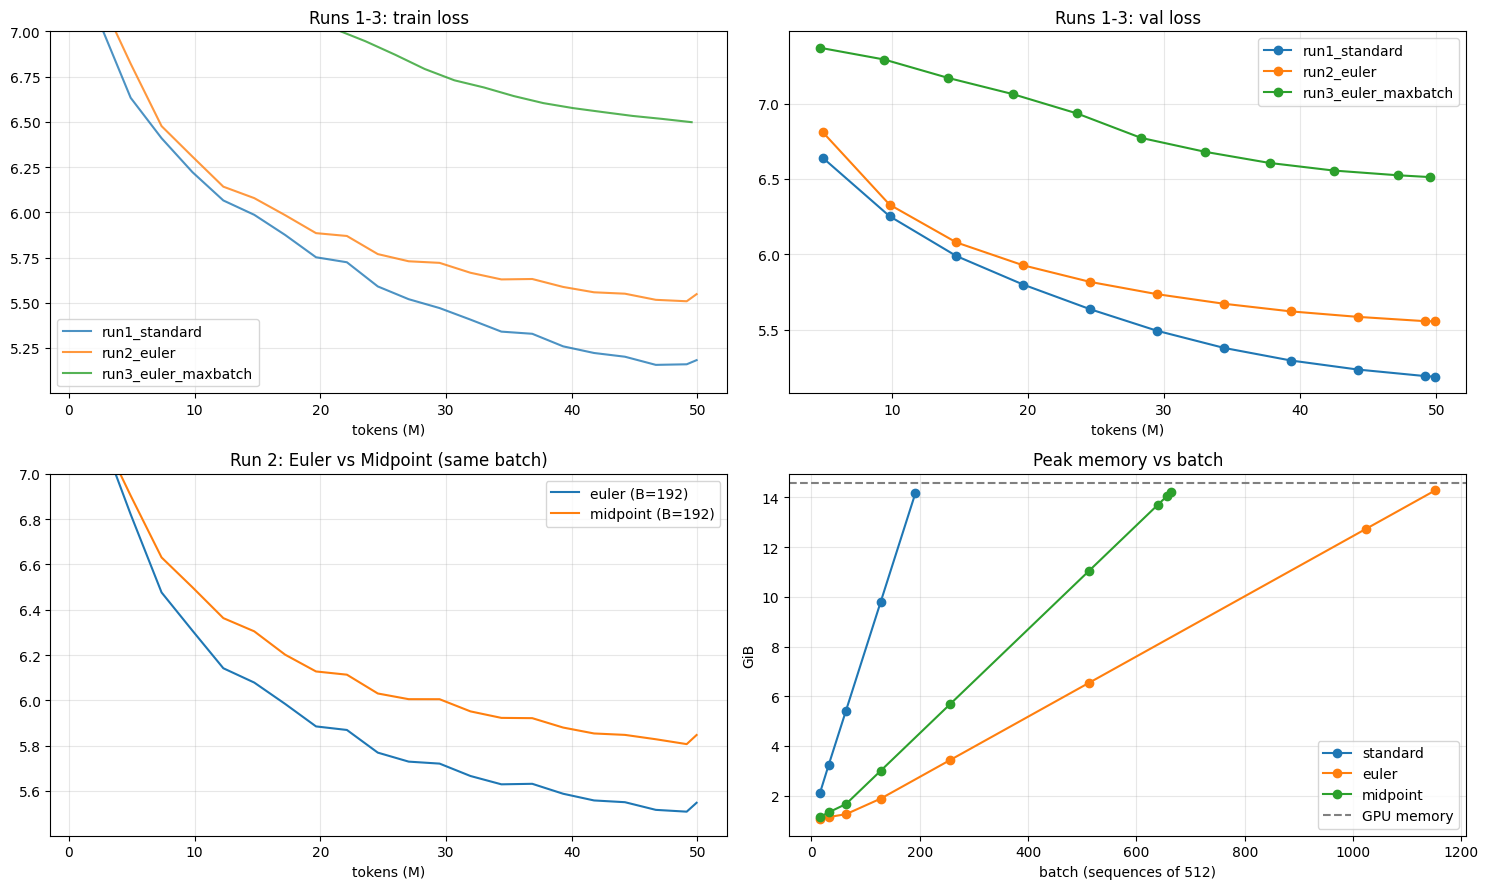

In [13]:
import pandas as pd, matplotlib.pyplot as plt
runs = [R1, R2, R3]
rows = []
for r in runs:
    rows.append({"run": r["name"], "rule": r["mode"] if r["mode"] == "standard" else f"{r['mode']} (h={r['h']})",
                 "batch": r["batch"], "tokens/step": r["batch"] * T, "steps": r["steps"], "peak LR": f"{r['lr']:.1e}",
                 "final val loss": round(r["final_val_loss"], 4), "final train loss": round(r["final_train_loss"], 4),
                 "tokens/s": int(r["tok_per_s"]), "peak alloc GiB": round(r["peak_mem_alloc_gib"], 2),
                 "peak reserved GiB": round(r["peak_mem_reserved_gib"], 2), "train min": round(r["train_time_s"] / 60, 1),
                 "est. $ / 50M tok": round(r["est_cost_50M_usd"], 3)})
df = pd.DataFrame(rows); display(df)
display(pd.DataFrame([{"variant": k, "tokens": f"{r['tokens']/1e6:.0f}M", "val loss": round(r["final_val_loss"], 4),
                       "tokens/s": int(r["tok_per_s"]), "peak GiB": round(r["peak_mem_alloc_gib"], 2),
                       "recon err": r["reconstruction_rel_err_after_training"]} for k, r in H2H.items()]))
display(pd.DataFrame([{"model": k, "max batch": v["max_batch"], "MiB / sequence": round(v["gib_per_seq"] * 1024, 1),
                       "x standard": round(v["max_batch"] / MAXB["standard"]["max_batch"], 2)} for k, v in MAXB.items()]))

fig, ax = plt.subplots(2, 2, figsize=(15, 9)); ax = ax.ravel()
for r in runs:
    ax[0].plot([l["tokens"] / 1e6 for l in r["log"]], [l["loss"] for l in r["log"]], label=r["name"], alpha=.8)
    ax[1].plot([e["tokens"] / 1e6 for e in r["evals"]], [e["val_loss"] for e in r["evals"]], "o-", label=r["name"])
for k, r in H2H.items():
    ax[2].plot([l["tokens"] / 1e6 for l in r["log"]], [l["loss"] for l in r["log"]], label=f"{k} (B={r['batch']})")
for k, v in MAXB.items():
    xs = sorted(int(b) for b in v["curve"]); ax[3].plot(xs, [v["curve"][str(b)] for b in xs], "o-", label=k)
ax[3].axhline(GPU_MEM_GIB, ls="--", c="gray", label="GPU memory")
ax[0].set(title="Runs 1-3: train loss", xlabel="tokens (M)", ylim=(None, 7))
ax[1].set(title="Runs 1-3: val loss", xlabel="tokens (M)")
ax[2].set(title="Run 2: Euler vs Midpoint (same batch)", xlabel="tokens (M)", ylim=(None, 7))
ax[3].set(title="Peak memory vs batch", xlabel="batch (sequences of 512)", ylabel="GiB")
for a in ax: a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/plots.png", dpi=130); plt.show()

In [14]:
summary = dict(env=json.load(open(f"{RESULTS_DIR}/env.json")), fixed_batch=CFG["fixed_batch"], params=N_PARAMS,
               best_variant=BEST, gpu_usd_per_hour=gpu_price(),
               runs=[{k: v for k, v in r.items() if k != "log"} for r in runs],
               head_to_head={k: {kk: vv for kk, vv in r.items() if kk not in ("log",)} for k, r in H2H.items()},
               max_batch=MAXB)
json.dump(summary, open(f"{RESULTS_DIR}/summary.json", "w"), indent=1)
shutil.make_archive(f"{BASE_DIR}/results", "zip", RESULTS_DIR)
print("=" * 25, "COPY EVERYTHING BELOW AND PASTE IT BACK", "=" * 25)
print(json.dumps(summary, separators=(",", ":"), default=str))
try:
    from google.colab import files; files.download(f"{BASE_DIR}/results.zip")
except Exception:
    print("download manually:", f"{BASE_DIR}/results.zip")

========================= COPY EVERYTHING BELOW AND PASTE IT BACK =========================
{"env":{"CFG":{"vocab_size":8192,"d_model":384,"n_layers":10,"n_heads":6,"seq_len":512,"total_tokens":50000000,"val_tokens":1000000,"fixed_batch":null,"base_lr":0.001,"min_lr_frac":0.1,"weight_decay":0.0,"betas":[0.9,0.95],"grad_clip":1.0,"warmup_frac":0.02,"lr_scale_rule":"sqrt","max_lr":0.003,"gpu_usd_per_hour":{"T4":0.35,"L4":0.7,"A100":1.8,"H100":2.5},"ce_chunk_tokens":8192,"eval_every_tokens":5000000,"eval_batches":40,"eval_batch":16,"sweep_tokens":5000000,"seed":1337},"VARIANTS":{"euler":{"mode":"euler","h":1.0,"gamma":1.0},"midpoint":{"mode":"midpoint","h":0.25,"gamma":1.0}},"gpu":"Tesla T4","gpu_mem_gib":14.56317138671875,"amp":"torch.float16","torch":"2.11.0+cu128"},"fixed_batch":192,"params":21053184,"best_variant":"euler","gpu_usd_per_hour":0.35,"runs":[{"name":"run1_standard","mode":"standard","h":1.0,"gamma":1.0,"batch":192,"seq_len":512,"tokens_per_step":98304,"steps":508,"lr":0.00

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>